# 08. KNN Classifier

**Project** · Fruit Classification  
**Problem type** · Classification

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

K-nearest neighbours identifies a class from nearby labelled examples. After making feature scales comparable, a new fruit can be classified by the votes of its closest training fruits.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

Fruit labels are sampled uniformly. Each label has its own average weight, sweetness, firmness and colour. Gaussian measurement variation creates overlap, particularly for apples and oranges. Grapes have a much smaller, tighter weight distribution.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `weight_g` | decimal | g | Weight of one fruit |
| `sweetness_brix` | decimal | °Bx | Soluble solids on a Brix scale |
| `firmness_score` | decimal | score from 1 to 10 | Synthetic firmness measure |
| `colour_score` | decimal | score from 0 to 100 | Synthetic colour index |
| `fruit` | string | Apple, Grape, Orange | Observed class label |

**Independent variables (X)** · `weight_g`, `sweetness_brix`, `firmness_score`, `colour_score`.

**Dependent variable (y)** · `fruit` is the class to predict. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "08_fruit_classification.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 5)


,weight_g,sweetness_brix,firmness_score,colour_score,fruit
0,190.30,7.77,4.24,79.27,Orange
1,189.74,14.10,7.24,40.88,Apple
2,154.29,10.08,5.31,51.30,Orange
3,144.09,12.33,7.27,25.72,Apple
4,6.79,15.62,4.41,49.68,Grape
5,8.74,12.72,4.78,37.02,Grape
6,126.97,10.83,7.16,68.98,Apple
7,180.20,9.44,4.02,70.98,Orange
8,10.30,17.64,3.15,38.40,Grape
9,11.33,16.26,4.08,48.88,Grape


weight_g          float64
sweetness_brix    float64
firmness_score    float64
colour_score      float64
fruit                 str
dtype: object

## 3. Mathematical Understanding

Euclidean distance between standardized feature rows $x$ and $z$ is $d(x,z)=\sqrt{\sum_{j=1}^p(x_j-z_j)^2}$, where $j$ indexes the $p$ features. Select the $K$ smallest distances, then use the class with the most votes. With uniform weights the class probability is its fraction of the $K$ votes.

For a fruit at coordinates $(0,0)$, training fruits at $(1,0)$, $(0,1)$ and $(2,2)$ have distances $1$, $1$ and $\sqrt{8}$. If they are Apple, Orange and Apple, $K=3$ gives two Apple votes and an Apple probability of $2/3$.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/neighbors.html)

## 4. Working Principle

Store the transformed training rows and their labels. Transform the new measurement with the training scaler. Find the closest examples and count their classes. Inspect the selected neighbours to understand whether the prediction comes from a consistent local group.

| Example | Distance | Vote |
| --- | --- | --- |
| Neighbour 1 | 1.00 | Apple |
| Neighbour 2 | 1.00 | Orange |
| Neighbour 3 | 2.83 | Apple |

**Workflow diagram**

`Raw input` → `Standardized numeric values and any category indicators` → `Votes among nearby labelled examples` → `Class prediction`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows class balance. Feature plots show variation. Pearson correlation measures linear association. The category target is excluded. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "fruit"
FEATURES = ["weight_g","sweetness_brix","firmness_score","colour_score"]
NUMERIC = ["weight_g","sweetness_brix","firmness_score","colour_score"]
CATEGORICAL = []
SEED = 42
LABELS = ["Apple","Grape","Orange"]

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   weight_g        1500 non-null   float64
 1   sweetness_brix  1500 non-null   float64
 2   firmness_score  1470 non-null   float64
 3   colour_score    1500 non-null   float64
 4   fruit           1500 non-null   str    
dtypes: float64(4), str(1)
memory usage: 66.6 KB


,weight_g,sweetness_brix,firmness_score,colour_score,fruit
0,190.30,7.77,4.24,79.27,Orange
1,189.74,14.10,7.24,40.88,Apple
2,154.29,10.08,5.31,51.30,Orange
3,144.09,12.33,7.27,25.72,Apple
4,6.79,15.62,4.41,49.68,Grape


,weight_g,sweetness_brix,firmness_score,colour_score,fruit
1495,8.12,17.74,3.95,30.83,Grape
1496,122.74,9.12,5.30,72.21,Orange
1497,7.07,18.15,4.08,41.39,Grape
1498,202.15,11.96,4.82,71.80,Orange
1499,269.82,13.55,4.43,65.86,Orange


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
weight_g,1500.0,NaN,NaN,NaN,115.193387,77.382286,2.0,9.52,143.25,175.3025,274.41
sweetness_brix,1500.0,NaN,NaN,NaN,13.49352,3.212478,4.19,11.0175,13.245,15.9225,23.59
firmness_score,1470.0,NaN,NaN,NaN,5.090367,1.513148,1.0,4.0,5.06,6.2375,9.32
colour_score,1500.0,NaN,NaN,NaN,55.919107,16.691913,6.94,44.3975,55.22,67.1425,100.0
fruit,1500,3,Orange,545,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing,Missing %
weight_g,0,0.0
sweetness_brix,0,0.0
firmness_score,30,2.0
colour_score,0,0.0
fruit,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

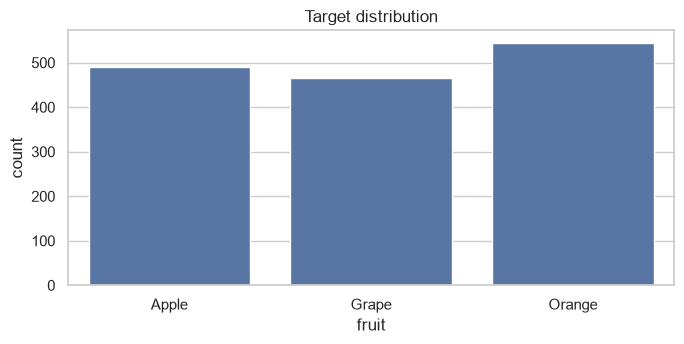

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.countplot(data=df, x=TARGET, order=LABELS, ax=ax)
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

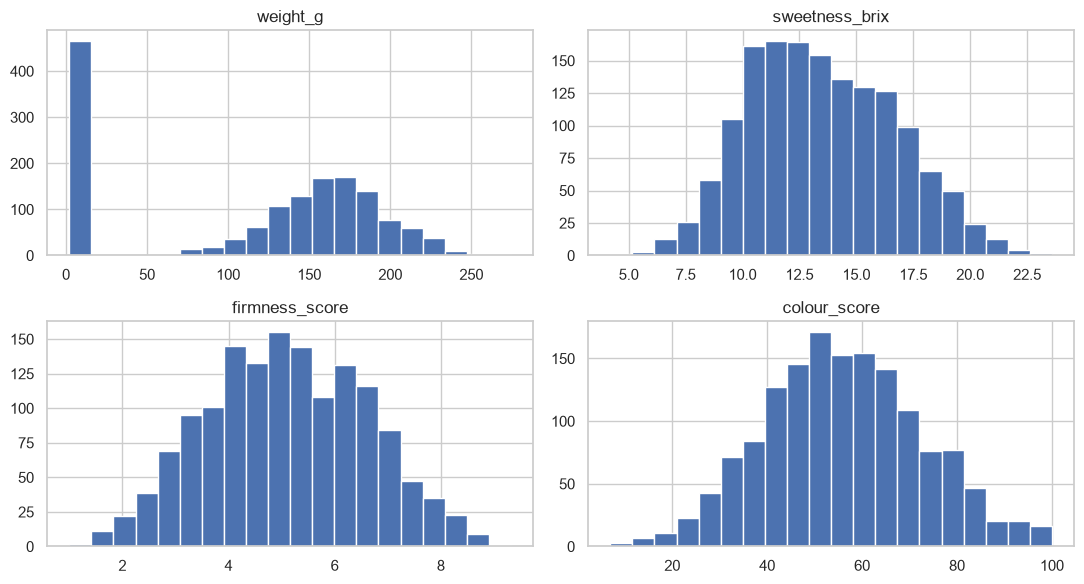

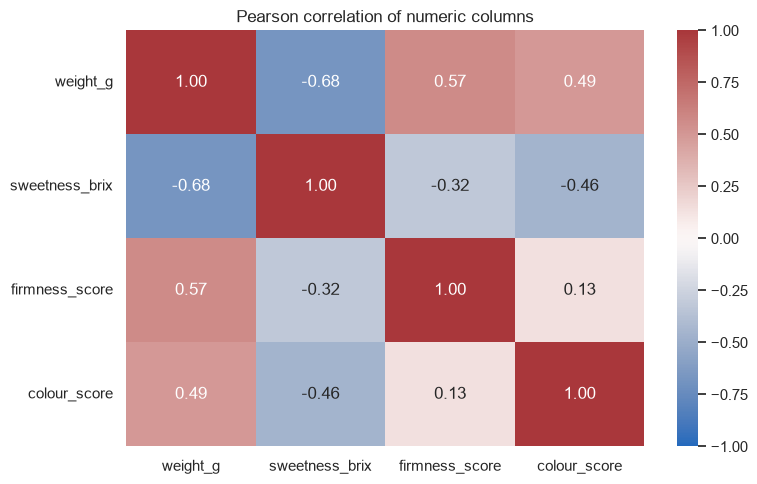

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. Stratification preserves approximate class proportions. The numeric branch fills blanks using training medians. This dataset has no categorical predictors. StandardScaler uses training means and standard deviations to make numeric magnitudes comparable. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
label_codes = {'Apple': 0, 'Grape': 1, 'Orange': 2}
y = df[TARGET].map(label_codes)

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Fill blank numbers, then put numeric columns on comparable scales.
numeric_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`n_neighbors` chooses K. `weights='uniform'` counts each neighbour equally while `distance` gives closer points more weight. With the Minkowski metric, `p=1` is Manhattan distance and `p=2` is Euclidean.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [9]:
from sklearn.neighbors import KNeighborsClassifier

estimator = KNeighborsClassifier(n_neighbors=9, weights="uniform", metric="minkowski", p=2)
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [10]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['weight_g','sweetness_brix','firmness_score','colour_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_o

### Predict on the test rows

In [11]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print("Example predicted class:", LABELS[predictions[0]])

,weight_g,sweetness_brix,firmness_score,colour_score
70,141.38,8.6,6.02,55.26


Example predicted class: Apple


## 8. Model Evaluation

Let $TP$ count correctly predicted positives, $TN$ correctly predicted negatives, $FP$ false positives, $FN$ false negatives and $N$ all test rows. Higher values indicate better scores, subject to the baseline and the costs of different errors.

| Measure | Formula and interpretation |
| --- | --- |
| Accuracy | $(TP+TN)/N$ for binary outcomes, or the proportion of correct predictions for multiple classes. |
| Precision | $TP/(TP+FP)$. Of the predicted positives, how many really were positive? |
| Recall | $TP/(TP+FN)$. Of the actual positives, how many did the model catch? |
| F1 | $2PR/(P+R)$ for precision $P$ and recall $R$. It is their harmonic mean. |
| ROC-AUC | Area $\int_0^1 \mathrm{TPR}\,d(\mathrm{FPR})$, with $\mathrm{TPR}=TP/(TP+FN)$ and $\mathrm{FPR}=FP/(FP+TN)$. Binary AUC measures the chance of ranking a random positive above a random negative, counting ties as half. Around 0.5 corresponds to chance ranking. |
| Confusion matrix | Entry $(i,j)$ counts rows with actual class $i$ and predicted class $j$. A strong diagonal indicates correct classifications. Examine the off-diagonal cells for costly errors. |
| Classification report | Applies precision, recall and F1 per class. Support counts actual examples per class. Macro averaging weights classes equally, and weighted averaging uses support. |

Compute the class-specific formulas one class against all others and take macro averages. ROC-AUC uses macro one-vs-rest on the probability columns. A prior-only classifier gives a baseline. A class with no positive predictions gets zero precision by convention.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)

AVERAGE = "macro"
CLASS_IDS = np.arange(len(LABELS))

test_scores = model.predict_proba(X_test)

initial_metrics = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores, multi_class="ovr", average="macro"),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

Accuracy     0.897
Precision    0.901
Recall       0.899
F1           0.899
ROC-AUC      0.966
Name: Test score, dtype: float64

### Compare with a simple baseline

In [13]:
# A baseline knows the training class frequencies and sees no input features.
baseline = DummyClassifier(strategy="prior")
baseline_train = np.zeros((len(y_train), 1))
baseline_test = np.zeros((len(y_test), 1))
baseline.fit(baseline_train, y_train)

baseline_predictions = baseline.predict(baseline_test)
baseline_scores = baseline.predict_proba(baseline_test)

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_scores, multi_class="ovr", average="macro"),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.363,0.121,0.333,0.178,0.500
Model,0.897,0.901,0.899,0.899,0.966


### Read the results for each class

In [14]:
print(classification_report(
    y_test, predictions, labels=CLASS_IDS, target_names=LABELS, zero_division=0
))

              precision    recall  f1-score   support

       Apple       0.87      0.81      0.84        98
       Grape       1.00      1.00      1.00        93
      Orange       0.84      0.89      0.86       109

    accuracy                           0.90       300
   macro avg       0.90      0.90      0.90       300
weighted avg       0.90      0.90      0.90       300



## 9. Visualizations

Read the confusion matrix by row for each actual class. Off-diagonal cells show the direction and size of confusions. Compare these counts with the class-specific scores in Section 8.

The bars show the distances and true classes of the nine neighbours for one held-out fruit. Distances use all four transformed features. Count the class names to recover the model’s vote.

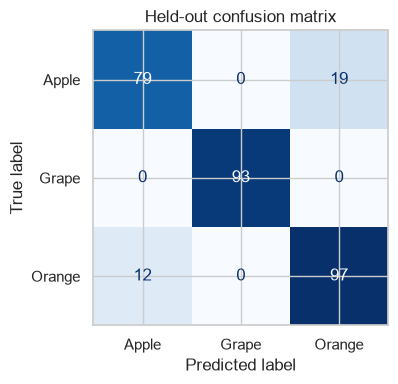

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=CLASS_IDS, display_labels=LABELS,
                                        colorbar=False, cmap="Blues", ax=ax)
ax.set_title("Held-out confusion matrix")
fig.tight_layout()
plt.show()

### A closer look at this model

,Rank,Distance,Fruit
0,1,0.437,Apple
1,2,0.475,Apple
2,3,0.502,Orange
3,4,0.538,Apple
4,5,0.597,Orange
5,6,0.601,Apple
6,7,0.620,Apple
7,8,0.623,Orange
8,9,0.633,Orange


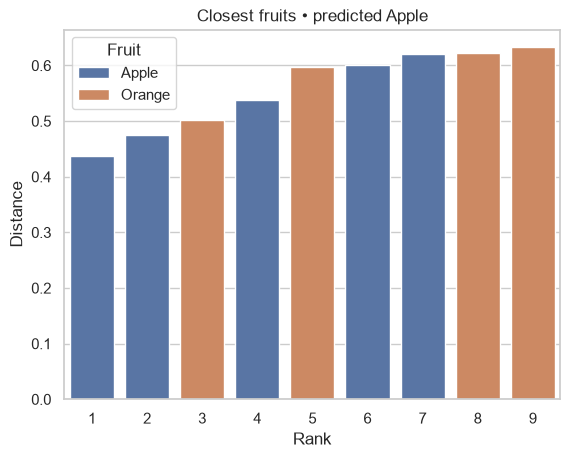

In [16]:
query = model.named_steps["preprocess"].transform(X_test.iloc[[0]])
distances, indices = model.named_steps["model"].kneighbors(query)
neighbors = pd.DataFrame({
    "Rank": np.arange(1, len(indices[0]) + 1),
    "Distance": distances[0],
    "Fruit": np.take(LABELS, y_train.iloc[indices[0]]),
})
display(neighbors.round(3))
fig, ax = plt.subplots()
sns.barplot(data=neighbors, x="Rank", y="Distance", hue="Fruit", dodge=False, ax=ax)
ax.set_title(f"Closest fruits • predicted {LABELS[predictions[0]]}")
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled stratified folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by macro F1. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`n_neighbors` chooses K. `weights='uniform'` counts each neighbour equally while `distance` gives closer points more weight. With the Minkowski metric, `p=1` is Manhattan distance and `p=2` is Euclidean.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {"model__n_neighbors": [3, 9, 21], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}
validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="f1_macro", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [18]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean CV F1"] = results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean CV F1", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__n_neighbors': 21, 'model__p': 1, 'model__weights': 'distance'}


,rank_test_score,Mean CV F1,std_test_score,params
9,1,0.911,0.015,"{'model__n_neighbors': 21, 'model__p': 1, 'mod..."
10,2,0.906,0.015,"{'model__n_neighbors': 21, 'model__p': 2, 'mod..."
8,3,0.906,0.017,"{'model__n_neighbors': 21, 'model__p': 1, 'mod..."
11,4,0.904,0.014,"{'model__n_neighbors': 21, 'model__p': 2, 'mod..."
5,5,0.901,0.013,"{'model__n_neighbors': 9, 'model__p': 1, 'mode..."


### Compare the models on the test set

In [19]:
tuned_predictions = tuned_model.predict(X_test)
tuned_scores = tuned_model.predict_proba(X_test)

tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tuned_scores, multi_class="ovr", average="macro"),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.363,0.121,0.333,0.178,0.500
First model,0.897,0.901,0.899,0.899,0.966
Tuned model,0.903,0.908,0.905,0.906,0.971


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. The result shows the estimated probability of each class. Read those estimates in the context of the synthetic population.

### Enter three new examples

In [20]:
examples = pd.DataFrame([
    [148, 13.4, 6.5, 53],
    [183, 10.6, 4.6, 76],
    [8.7, 17.8, 3.4, 42],
], columns=FEATURES)
display(examples)

,weight_g,sweetness_brix,firmness_score,colour_score
0,148.0,13.4,6.5,53
1,183.0,10.6,4.6,76
2,8.7,17.8,3.4,42


### Make predictions

In [21]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Apple-like measurement","Orange-like measurement","Grape-like measurement"]
probabilities = prediction_model.predict_proba(sample_inputs)
example_output["Predicted class"] = np.take(LABELS, sample_predictions)

# Each row contains the class probabilities for one new example.
probability_table = pd.DataFrame(probabilities.round(3), columns=LABELS)
probability_table = probability_table.add_prefix("P(").add_suffix(")")
example_output = pd.concat([example_output, probability_table], axis=1)
display(example_output)

,weight_g,sweetness_brix,firmness_score,colour_score,Scenario,Predicted class,P(Apple),P(Grape),P(Orange)
0,148.0,13.4,6.5,53,Apple-like measurement,Apple,0.922,0.0,0.078
1,183.0,10.6,4.6,76,Orange-like measurement,Orange,0.039,0.0,0.961
2,8.7,17.8,3.4,42,Grape-like measurement,Grape,0.000,1.0,0.000


## 12. Limitations and Advantages

KNN learns local boundaries and makes examples available for inspection. Its distance assumes the chosen scales reflect similarity. Small K is sensitive to noise, large K can wash out minority regions, and test-time searches grow costly with more rows or dimensions. Use for small, low-dimensional datasets with meaningful distances. For sparse high-dimensional or latency-sensitive tasks, compare other models.

## 13. Interview Preparation

### A. 30-second explanation

> I classified apples, oranges and grapes from four measurements. KNN stores training examples and votes using the closest standardized points. I cross-validated K, weights and the distance metric, then examined per-class errors and the neighbours of a sample fruit.

### B. 90-second technical explanation

> I classified apples, oranges and grapes from four measurements. KNN stores training examples and votes using the closest standardized points. I cross-validated K, weights and the distance metric, then examined per-class errors and the neighbours of a sample fruit. My target was fruit, and the inputs were weight g, sweetness brix, firmness score, colour score. Store the transformed training rows and their labels. Transform the new measurement with the training scaler. Find the closest examples and count their classes. Inspect the selected neighbours to understand whether the prediction comes from a consistent local group. I held out 20% of the rows and fitted preprocessing within each training fold. I compared F1 and ROC-AUC with a prior baseline and read the confusion matrix to identify the classes that were easiest to confuse. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **What is K?** The number of training neighbours contributing to a prediction.
2. **Why standardize before computing distances?** Otherwise large numeric scales can dominate similarity.
3. **Why is KNN called lazy learning?** It mainly stores the training examples and performs the neighbour search at prediction time.
4. **What does a very small K do?** It produces a flexible, potentially noisy boundary.
5. **What does a large K do?** It averages larger regions, potentially biasing predictions toward common classes.
6. **What is Manhattan distance?** The sum of absolute coordinate differences.
7. **How are uniform probabilities formed?** Count votes for each class and divide by K.
8. **Can an odd K prevent every tie?** No. Three or more classes can tie even when K is odd.
9. **What is the curse of dimensionality?** Local neighbourhoods become less informative as data spreads across more dimensions.
10. **Why inspect macro F1?** It weights each fruit class equally.

### D. Five scenario questions

1. **Apple and Orange overlap. What would you report?** Inspect their confusion and see whether measured features separate those fruits.
2. **Weight ranges from 2 to 300 while firmness ranges from 1 to 10. What helps?** Fit scaling within training folds.
3. **Some training fruits have incorrect labels. What would you change?** Audit the labels and compare larger K or less aggressive distance weighting.
4. **Prediction latency rises as the collection grows. What would you investigate?** Measure search time and consider a different index or model.
5. **You add many random colour channels. What might happen?** Noise may distort distance, so validate a smaller feature set.

### E. Three common mistakes

- Tuning K on test labels. Use cross-validation.
- Calculating distance in raw units. Use training-fitted scaling.
- Inferring every split in four dimensions from a two-variable plot. Treat it as a projection.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [22]:
from IPython.display import Markdown

summary = (
    "I built a supervised classification project for fruit classification using KNN Classifier. I generated 1,500 synthetic observations and used weight g, sweetness brix, firmness score, colour score to predict fruit. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model reached {tuned_metrics['F1']:.3f} macro F1, versus "
    f"{baseline_metrics['F1']:.3f} for the baseline, with ROC-AUC {tuned_metrics['ROC-AUC']:.3f}. "
    "I inspected the closest measured fruits and counted how they voted. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised classification project for fruit classification using KNN Classifier. I generated 1,500 synthetic observations and used weight g, sweetness brix, firmness score, colour score to predict fruit. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model reached 0.906 macro F1, versus 0.178 for the baseline, with ROC-AUC 0.971. I inspected the closest measured fruits and counted how they voted. These results apply to the synthetic data and should be validated on representative observations before practical use.